In [4]:
%pip install xlrd

Note: you may need to restart the kernel to use updated packages.


In [4]:
import pandas as pd

df = pd.read_excel(
    "Concrete_Data.xls"
    
)

print(df.head())
print(df.shape)


   Cement (component 1)(kg in a m^3 mixture)  \
0                                      540.0   
1                                      540.0   
2                                      332.5   
3                                      332.5   
4                                      198.6   

   Blast Furnace Slag (component 2)(kg in a m^3 mixture)  \
0                                                0.0       
1                                                0.0       
2                                              142.5       
3                                              142.5       
4                                              132.4       

   Fly Ash (component 3)(kg in a m^3 mixture)  \
0                                         0.0   
1                                         0.0   
2                                         0.0   
3                                         0.0   
4                                         0.0   

   Water  (component 4)(kg in a m^3 mixture)  \
0      

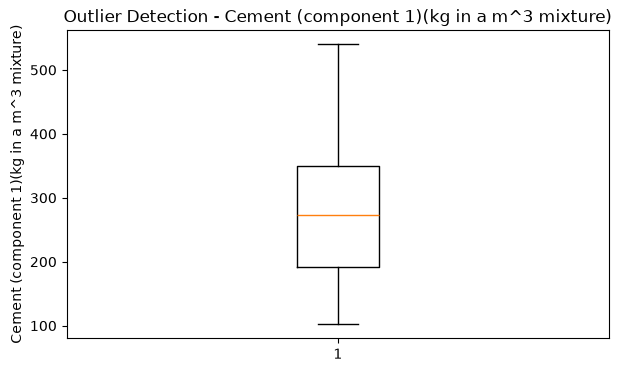

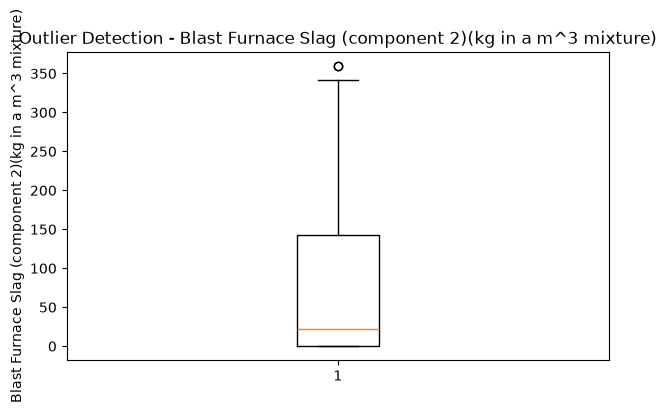

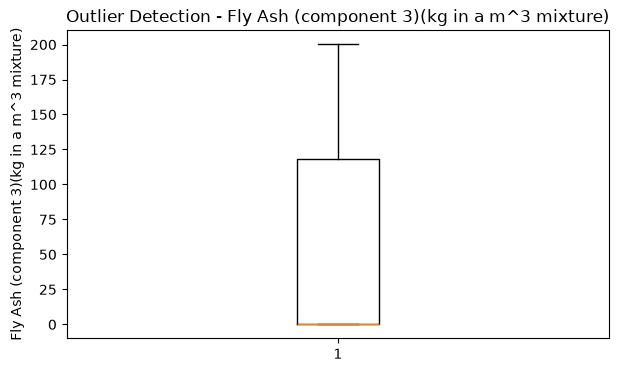

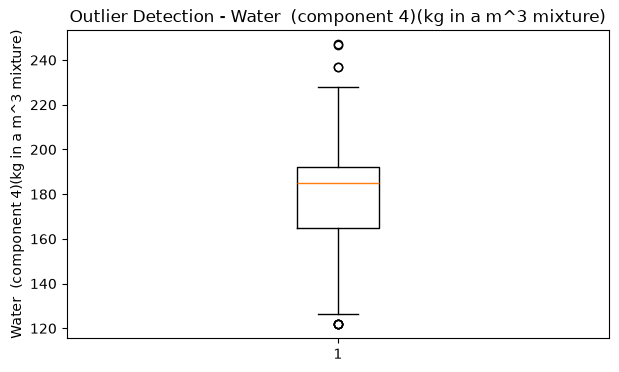

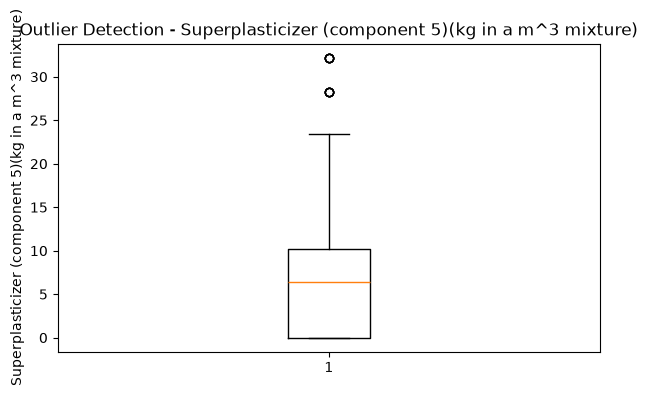

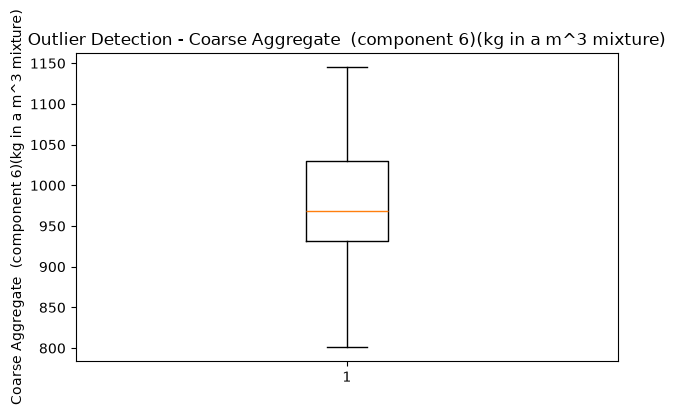

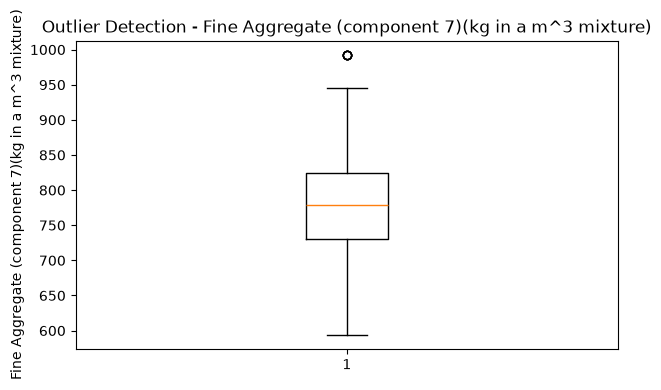

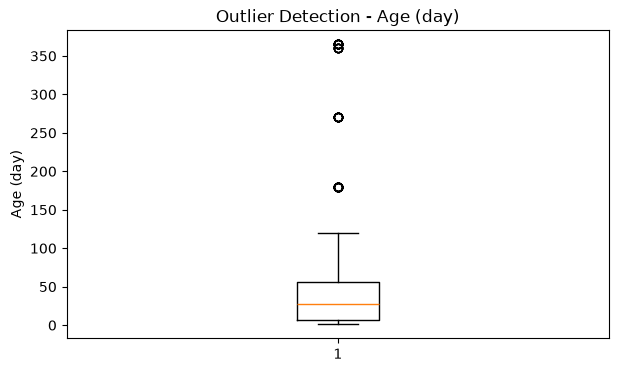

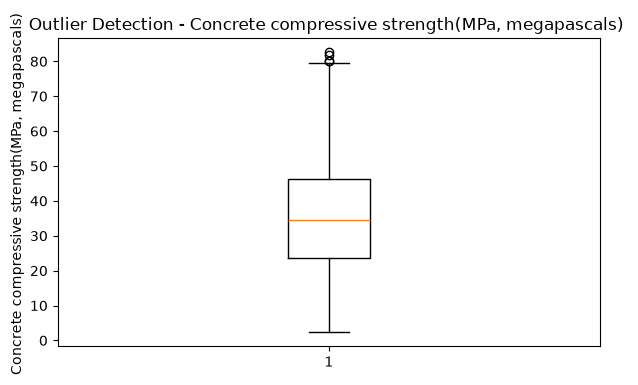

In [7]:
import matplotlib.pyplot as plt
import numpy as np
for col in df.select_dtypes(include=np.number).columns:
    q1=df[col].quantile(0.25)
    q3=df[col].quantile(0.75)
    IQR=q3-q1
    lower=q1-1.5*IQR
    upper=q3+1.5*IQR
    outlier=outliers = df[
        (df[col] < lower) | (df[col] > upper)
    ]
    plt.figure(figsize=(7, 4))

    plt.boxplot(df[col].dropna())

    plt.title(f"Outlier Detection - {col}")
    plt.ylabel(col)

    plt.show()

In [9]:
numeric_cols = df.select_dtypes(include=np.number).columns

# Calculate statistics
result = pd.DataFrame({
    "Mean": df[numeric_cols].mean(),
    "Median": df[numeric_cols].median(),
    "Std": df[numeric_cols].std(),
    "Skewness": df[numeric_cols].skew()})

print(result.round(2))

                                                      Mean  Median     Std  \
Cement (component 1)(kg in a m^3 mixture)           281.17  272.90  104.51   
Blast Furnace Slag (component 2)(kg in a m^3 mi...   73.90   22.00   86.28   
Fly Ash (component 3)(kg in a m^3 mixture)           54.19    0.00   64.00   
Water  (component 4)(kg in a m^3 mixture)           181.57  185.00   21.36   
Superplasticizer (component 5)(kg in a m^3 mixt...    6.20    6.35    5.97   
Coarse Aggregate  (component 6)(kg in a m^3 mix...  972.92  968.00   77.75   
Fine Aggregate (component 7)(kg in a m^3 mixture)   773.58  779.51   80.18   
Age (day)                                            45.66   28.00   63.17   
Concrete compressive strength(MPa, megapascals)      35.82   34.44   16.71   

                                                    Skewness  
Cement (component 1)(kg in a m^3 mixture)               0.51  
Blast Furnace Slag (component 2)(kg in a m^3 mi...      0.80  
Fly Ash (component 3)(kg in a 

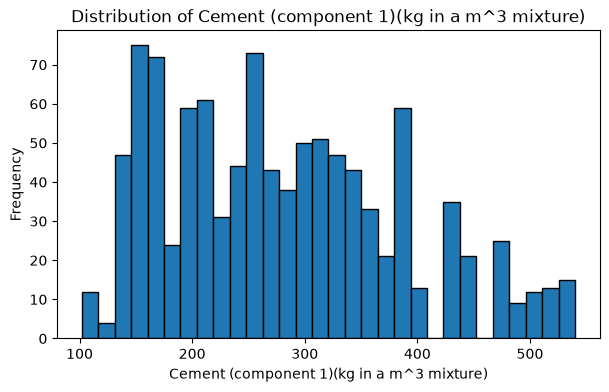

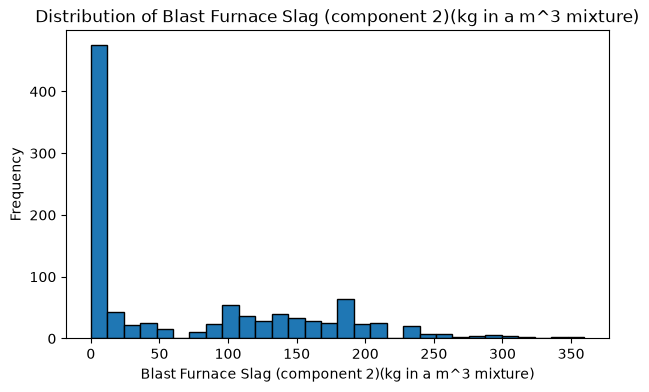

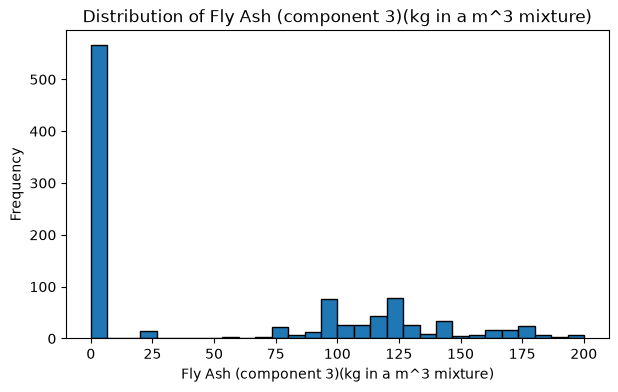

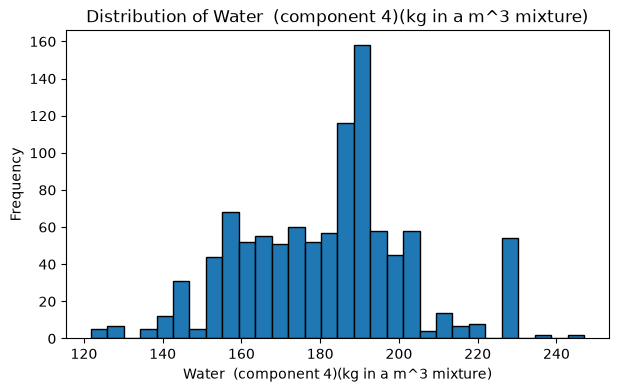

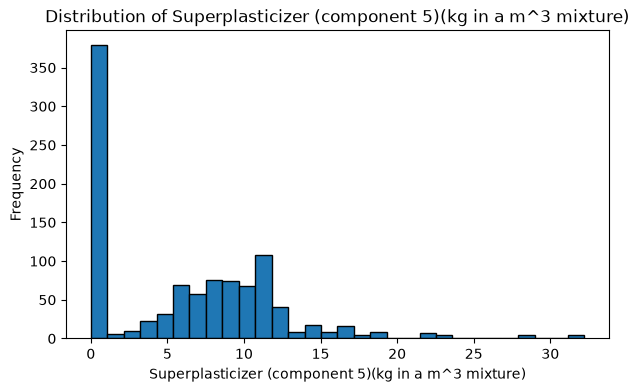

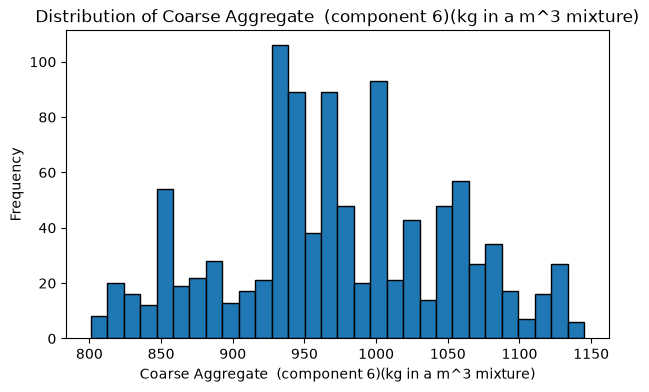

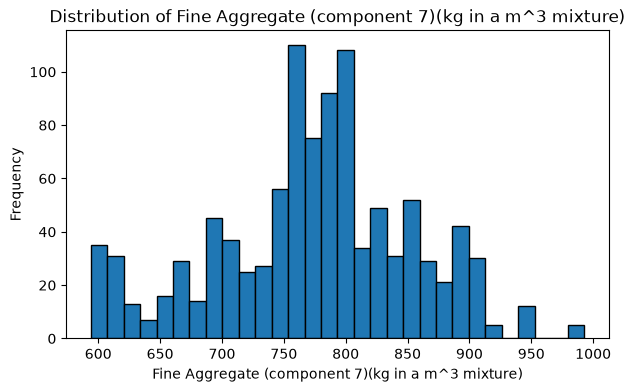

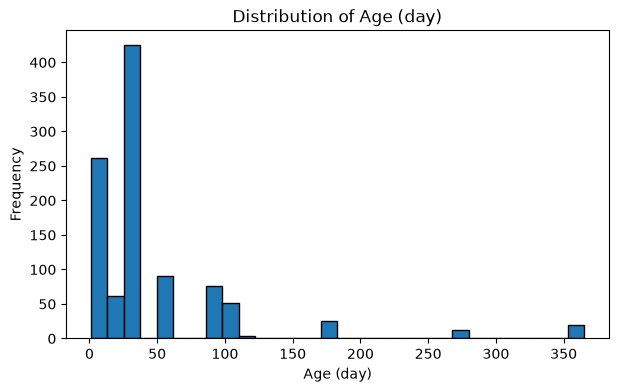

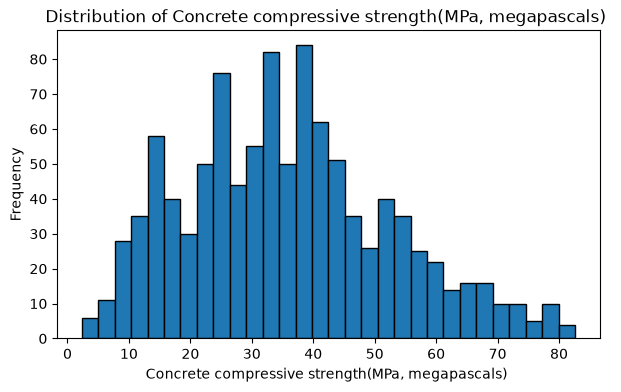

In [10]:
import matplotlib.pyplot as plt

for col in numeric_cols:

    plt.figure(figsize=(7, 4))

    plt.hist(df[col], bins=30, edgecolor="black")

    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Frequency")

    plt.show()

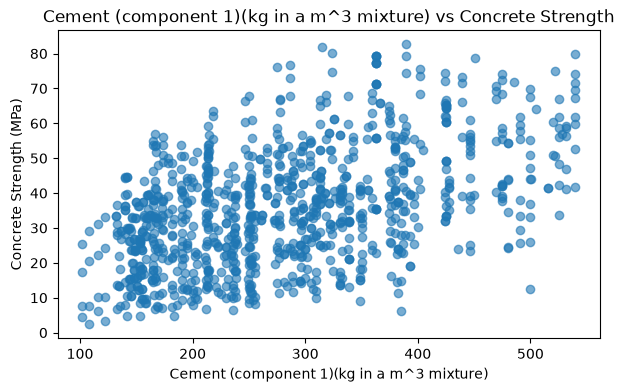

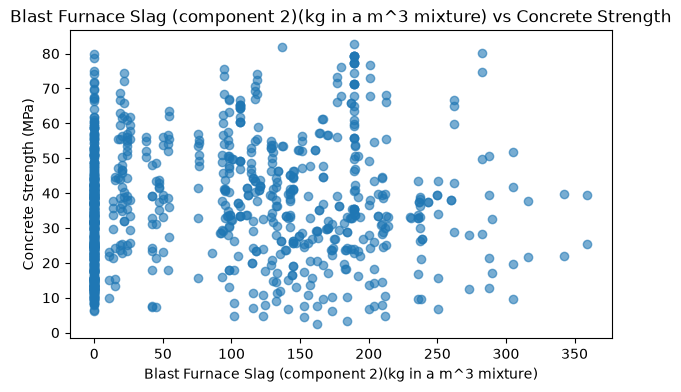

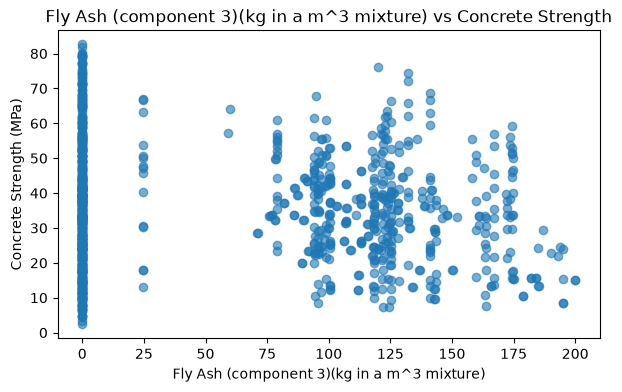

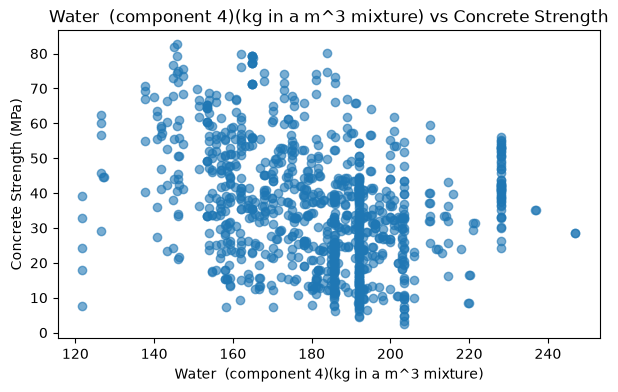

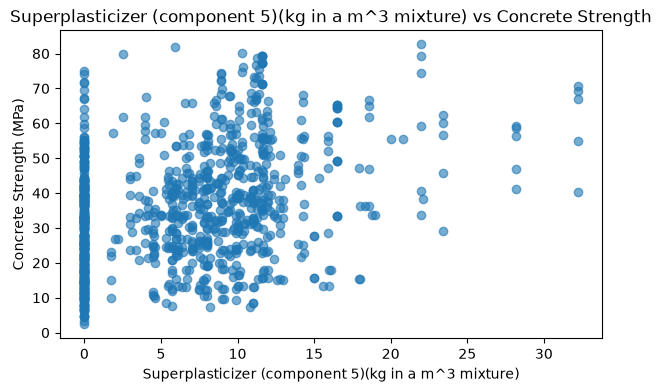

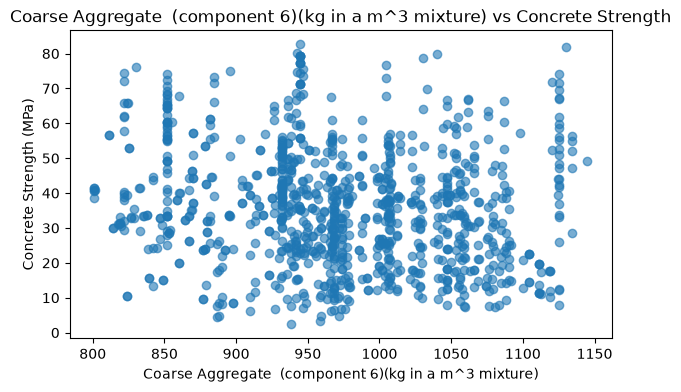

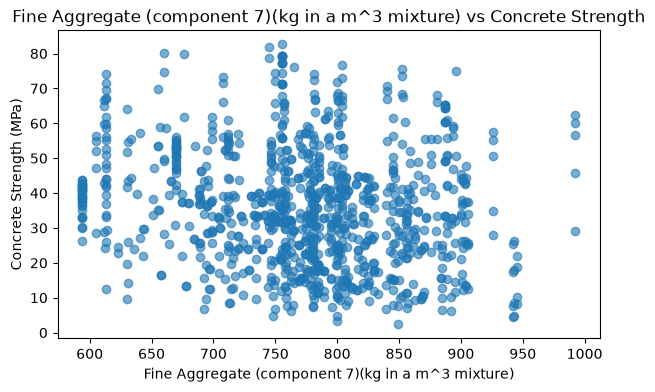

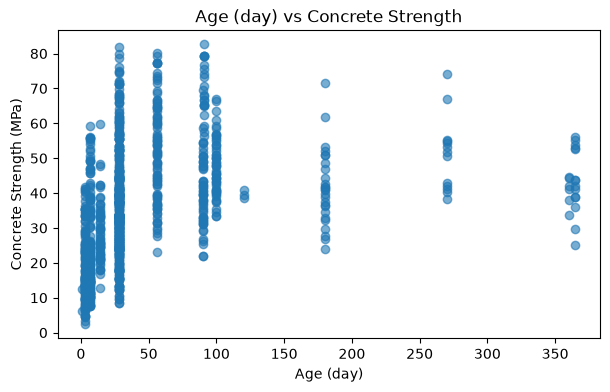

In [13]:
target = df.columns[-1]

features = df.drop(columns=[target]).select_dtypes(include="number").columns

for col in features:

    plt.figure(figsize=(7, 4))

    plt.scatter(df[col], df[target], alpha=0.6)

    plt.xlabel(col)
    plt.ylabel("Concrete Strength (MPa)")
    plt.title(f"{col} vs Concrete Strength")

    plt.show()

In [18]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline
from sklearn.model_selection import KFold, cross_val_score
target=df.columns[-1]
X=df.drop(columns=[target])
y=df[target]

X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)

degree=[1,2,3,4,5]
kf=KFold(n_splits=5,shuffle=True,random_state=42)
results=[]
for degree in degree:
    model=Pipeline([("poly",PolynomialFeatures(degree=degree,include_bias=False)),("scale",StandardScaler()),("regression",LinearRegression())])
 
    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=kf,
        scoring="neg_mean_squared_error"
    )

    mse_scores = -scores
    results.append({
        "Degree": degree,
        "Mean CV MSE": mse_scores.mean(),
        "Standard Deviation": mse_scores.std()
    })

results_df = pd.DataFrame(results)

print(results_df)

   Degree   Mean CV MSE  Standard Deviation
0       1    113.176723           10.280769
1       2     63.302729            8.806826
2       3     60.898022           22.711924
3       4   1143.067914          742.631616
4       5  25229.472390        25562.106126


In [20]:
best_model = Pipeline([
    ("poly", PolynomialFeatures(
        degree=3,
        include_bias=False
    )),
    ("scaler", StandardScaler()),
    ("regression", LinearRegression())
])

best_model.fit(X_train, y_train)

from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

y_pred = best_model.predict(X_test)
print("pridicted",y_pred[:10])
print("actual",y_test[:10])

print("Test MSE:", mean_squared_error(y_test, y_pred))
print("Test RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))
print("Test MAE:", mean_absolute_error(y_test, y_pred))
print("Test R2:", r2_score(y_test, y_pred))

pridicted [59.17318848 44.22384329 70.91531271 40.37426248 11.76125108 44.22424649
 28.97631785 53.377552   33.32752606 47.34762627]
actual 31      52.908320
109     55.895819
136     74.497882
88      35.301171
918     10.535193
1025    44.284354
870     23.690395
318     45.367521
261     37.404073
535     48.846617
Name: Concrete compressive strength(MPa, megapascals) , dtype: float64
Test MSE: 41.21897322478291
Test RMSE: 6.4202004037867
Test MAE: 4.738305022472672
Test R2: 0.8400388110369297
